## Лабораторная работа №1 | Вариант 5

Выполнил: 

### 1. Numpy

In [33]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [34]:
matrix = np.eye(3)
matrix 

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [35]:
pixel_rgba_type = np.dtype([('r', np.uint8), ('g', np.uint8), ('b', np.uint8), ('a', np.uint8)])

3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [36]:
previous_settings = np.seterr(all="ignore")
previous_settings

{'divide': 'ignore', 'over': 'ignore', 'under': 'ignore', 'invalid': 'ignore'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [37]:
rng = np.random.default_rng(42)

rand_vec =   rng.random(10)
sorted_vec = np.sort(rand_vec)
sorted_vec
 

array([0.09417735, 0.12811363, 0.43887844, 0.45038594, 0.69736803,
       0.7611397 , 0.77395605, 0.78606431, 0.85859792, 0.97562235])

5. Создайте read-only массив(неизменяемый)

In [38]:
arrayRO = np.arange(5)
arrayRO.flags.writeable = False

6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [39]:
points = rng.random((10, 2))
x, y = points[:, 0], points[:, 1]

radius = np.hypot(x, y)
angle = np.arctan2(y, x)
polar = np.column_stack((radius, angle))
polar

array([[0.99819062, 1.19020435],
       [1.04474828, 0.90677675],
       [0.49825053, 0.47357778],
       [0.55824451, 0.11456822],
       [1.04114037, 0.65190816],
       [0.83689048, 0.43744109],
       [1.31906027, 0.74379963],
       [0.80234973, 0.24503045],
       [0.46877208, 0.09358016],
       [0.7002579 , 1.34864111]])

7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [40]:
grid = np.zeros((10, 10), dtype=[('x', float), ('y', float)])
grid['x'], grid['y'] = np.meshgrid(np.linspace(0, 1, 10), np.linspace(0, 1, 10))


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [41]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

C = 1 / (x[:, None] - y[None, :])
C

array([[-0.49268319, -1.05273036, -0.30252139, -0.44184015, 15.33226156],
       [-0.39286266, -0.68230149, -0.26169322, -0.35984441, -2.21978068],
       [57.8586356 ,  0.91151509, -0.79455506, -4.62370932,  0.47343837],
       [-0.67611464, -2.5047083 , -0.36299108, -0.58390778,  1.62368048],
       [ 2.69286419,  0.68911203, -1.10558599,  7.25732919,  0.40546968]])

9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [42]:
array_flt = np.array([1.111, 42.690, 67.676767], dtype=np.float32)
int_view = array_flt.view(np.int32)

10. Как случайно заменить p элементов в 2D массиве?

In [43]:
array = np.arange(100).reshape(4, 25)
p = 4

indices = rng.choice(array.size, size=p, replace=False)
array.flat[indices] = -1
array

array([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
        16, 17, 18, 19, 20, 21, 22, 23, 24],
       [25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, -1, 37, 38, 39, 40,
        41, 42, 43, 44, 45, 46, 47, 48, 49],
       [50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65,
        66, 67, 68, 69, 70, 71, -1, 73, 74],
       [75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, -1, 90,
        91, 92, 93, 94, 95, -1, 97, 98, 99]])

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [44]:
import pandas as pd

In [45]:
df = pd.read_csv("data.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


1. Узнайте сколько было на борту человек

In [46]:
len(df)

891

2. Какой медианный и средний возраста пассажиров

In [47]:
df["Age"].agg(["mean","median"])

mean      29.699118
median    28.000000
Name: Age, dtype: float64

3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [48]:
known_age = df.dropna(subset=["Age"])

children = known_age[known_age["Age"] < 16]
adults = known_age[known_age["Age"] >= 16]

pd.Series({
    "Дети": children["Survived"].mean() * 100,
    "Взрослые": adults["Survived"].mean() * 100
})

Дети        59.036145
Взрослые    38.193344
dtype: float64

4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [49]:
groups = known_age.copy()
groups["Group"] = "Взрослые мужчины"
groups.loc[groups["Sex"] == "female", "Group"] = "Взрослые женщины"
groups.loc[groups["Age"] < 16, "Group"] = "Дети"

groups.groupby("Group")["Survived"].agg(["count", "mean"])

,count,mean
Group,,
Взрослые женщины,218,0.775229
Взрослые мужчины,413,0.174334
Дети,83,0.590361


5. Зависит ли выживаемость от класса обслуживания?

In [50]:
survival_by_class = df.groupby("Pclass")["Survived"].mean()
survival_by_class

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

6. Посчитайте средний возраст умерших женщин и мужчин

In [51]:
dead = df[df["Survived"] == 0]
mean_age_dead = dead.groupby("Sex")["Age"].mean()
mean_age_dead

Sex
female    25.046875
male      31.618056
Name: Age, dtype: float64

7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [52]:
relatives_count = df["SibSp"] + df["Parch"]
with_family = df[relatives_count > 0]
alone = df[relatives_count == 0]

print(f"С родственниками: {with_family['Survived'].mean() * 100:.2f}%")
print(f"Без родственников: {alone['Survived'].mean() * 100:.2f}%")

С родственниками: 50.56%
Без родственников: 30.35%


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [53]:
fare_by_survival = df.groupby("Survived")["Fare"].mean()
print(fare_by_survival)

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [54]:
selected = df[
    (df["Survived"] == 1) & (df["Pclass"] == 2)
]
print(f"Минимальный возраст среди выживших пассажиров второго класса: {selected['Age'].min()} лет")
print(f"Максимальный возраст среди выживших пассажиров второго класса: {selected['Age'].max()} лет")

Минимальный возраст среди выживших пассажиров второго класса: 0.67 лет
Максимальный возраст среди выживших пассажиров второго класса: 62.0 лет


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [55]:
adult_men = df[
    (df["Sex"] == "male") & (df["Age"] >= 18)
]
# Примем более молодыми от 18 до 40 лет
young_men = adult_men[adult_men["Age"] < 40]
older_men = adult_men[adult_men["Age"] >= 40]

print("Количество мужчин 18–29 лет:", len(young_men))
print("Количество мужчин 40+:", len(older_men))

print(f"Выживаемость 18–29 лет: {young_men['Survived'].mean() * 100:.2f}%")
print(f"Выживаемость старше 40 лет: {older_men['Survived'].mean() * 100:.2f}%")

Количество мужчин 18–29 лет: 286
Количество мужчин 40+: 109
Выживаемость 18–29 лет: 17.83%
Выживаемость старше 40 лет: 17.43%


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

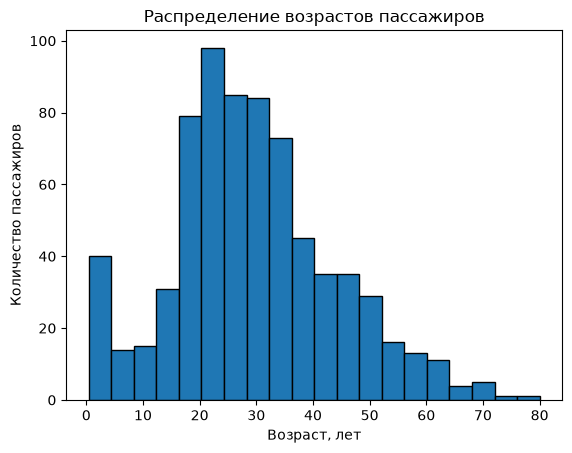

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns


plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Распределение возрастов пассажиров")
plt.xlabel("Возраст, лет")
plt.ylabel("Количество пассажиров")
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

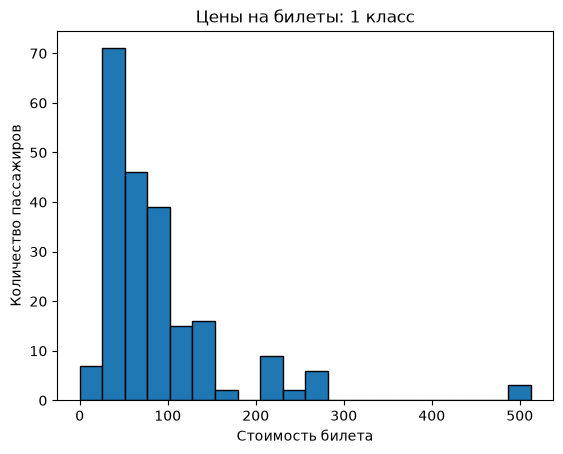

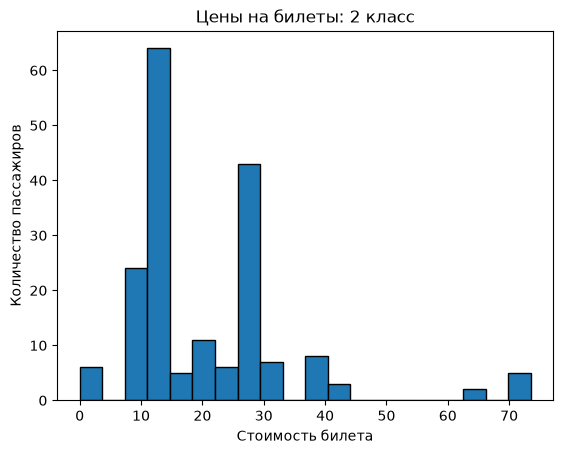

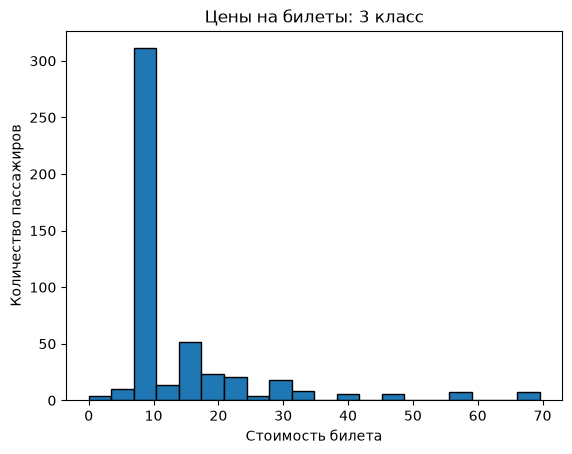

In [57]:
for passenger_class in [1, 2, 3]:
    fares = df[df["Pclass"] == passenger_class]["Fare"]

    plt.figure()
    plt.hist(fares, bins=20, edgecolor="black")
    plt.title(f"Цены на билеты: {passenger_class} класс")
    plt.xlabel("Стоимость билета")
    plt.ylabel("Количество пассажиров")
    plt.show()

3. Постройте зависимость цены от возраста пассажира

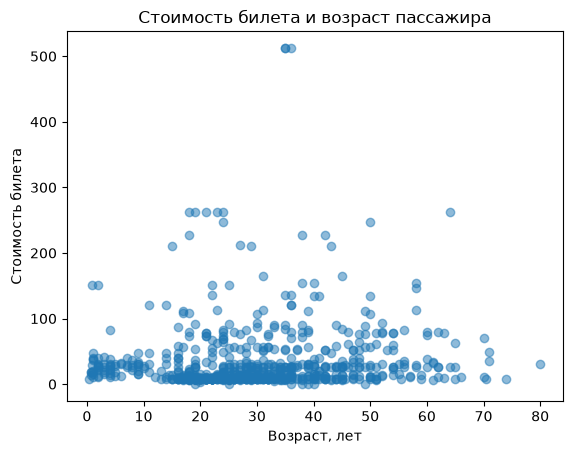

In [58]:
plt.scatter(df["Age"], df["Fare"], alpha=0.5)

plt.title("Стоимость билета и возраст пассажира")
plt.xlabel("Возраст, лет")
plt.ylabel("Стоимость билета")
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

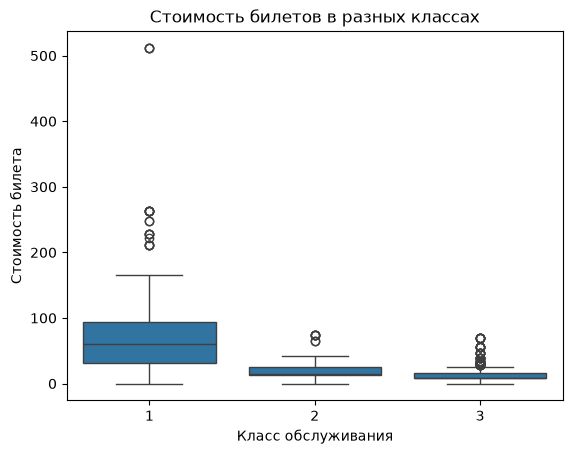

In [59]:
sns.boxplot(data=df, x="Pclass", y="Fare")

plt.title("Стоимость билетов в разных классах")
plt.xlabel("Класс обслуживания")
plt.ylabel("Стоимость билета")
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

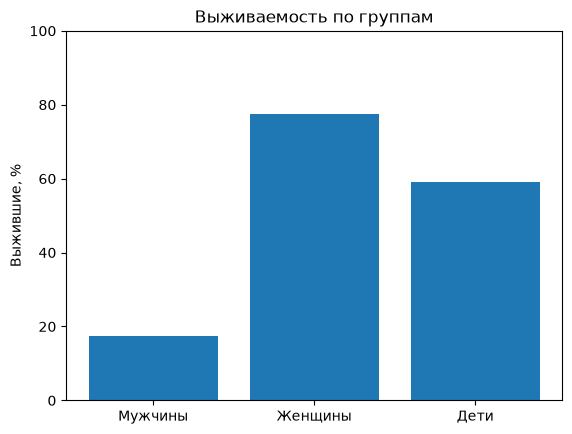

In [60]:
men = df[(df["Sex"] == "male") & (df["Age"] >= 16)]
women = df[(df["Sex"] == "female") & (df["Age"] >= 16)]
children = df[df["Age"] < 16]

rates = [
    men["Survived"].mean() * 100,
    women["Survived"].mean() * 100,
    children["Survived"].mean() * 100
]

plt.bar(["Мужчины", "Женщины", "Дети"], rates)

plt.title("Выживаемость по группам")
plt.ylabel("Выжившие, %")
plt.ylim(0, 100)
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

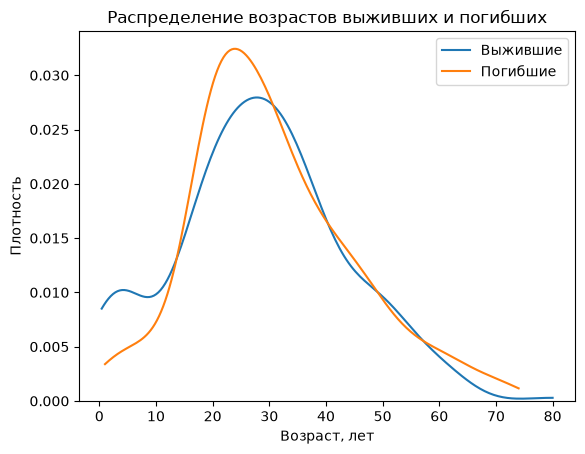

In [61]:
survived = df[df["Survived"] == 1]
dead = df[df["Survived"] == 0]

sns.kdeplot(data=survived, x="Age", label="Выжившие", cut=0)
sns.kdeplot(data=dead, x="Age", label="Погибшие", cut=0)

plt.title("Распределение возрастов выживших и погибших")
plt.xlabel("Возраст, лет")
plt.ylabel("Плотность")
plt.legend()
plt.show()

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

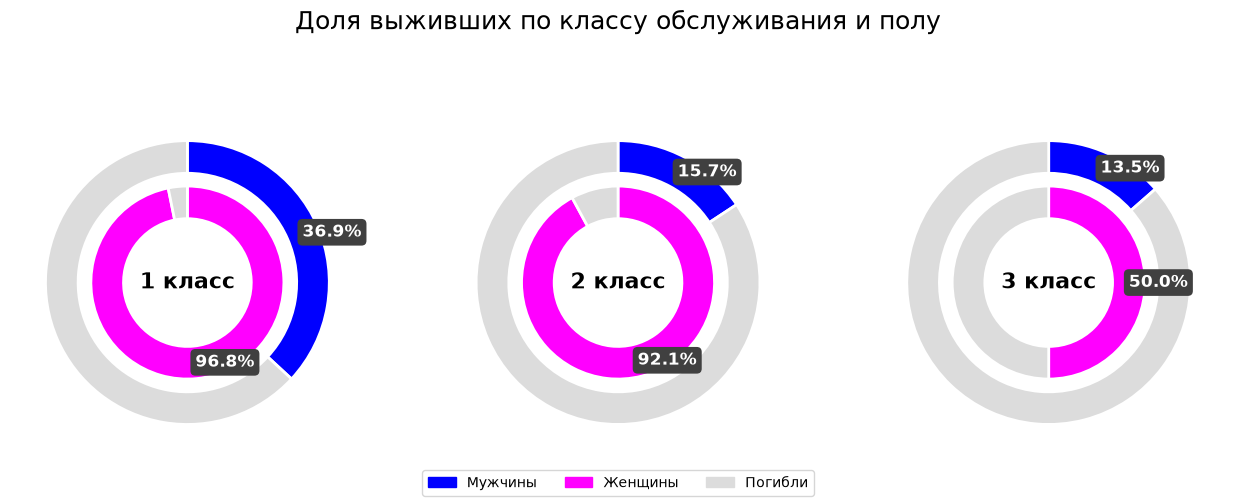

In [93]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

ring_params = [
    ("male", 1, "blue"),
    ("female", 0.68, "magenta")
]

for ax, passenger_class in zip(axes, [1, 2, 3]):
    for sex, radius, color in ring_params:
        passengers = df[
            (df["Pclass"] == passenger_class) & (df["Sex"] == sex)
        ]

        percent_survived = passengers["Survived"].mean() * 100

        ax.pie(
            [percent_survived, 100 - percent_survived],
            radius=radius,
            colors=[color, "gainsboro"],
            startangle=90,
            counterclock=False,
            wedgeprops={
                "width": 0.23,
                "edgecolor": "white",
                "linewidth": 2
            }
        )

        # Середина дуги
        angle = np.deg2rad(90 - 180 * percent_survived / 100)
        text_radius = radius - 0.23 / 2

        ax.text(
            text_radius * np.cos(angle),
            text_radius * np.sin(angle),
            f"{percent_survived:.1f}%",
            ha="left",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white",
            bbox={
                "boxstyle": "round,pad=0.3",
                "facecolor": "#404040",
                "edgecolor": "none"
            }
        )

    ax.text(
        0, 0,
        f"{passenger_class} класс",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold"
    )

fig.suptitle("Доля выживших по классу обслуживания и полу", fontsize=18)

fig.legend(
    handles=[
        Patch(color="blue", label="Мужчины"),
        Patch(color="magenta", label="Женщины"),
        Patch(color="gainsboro", label="Погибли")
    ],
    loc="lower center",
    ncol=3,
)

plt.tight_layout(rect=[0, 0.05, 1, 0.9])
plt.show()